In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import pandas as pd

df = pd.read_csv("store_sales.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7300, 5)


In [4]:
import os

print(os.getcwd())

C:\Users\Lenovo


Libraries imported successfully!

Dataset loaded successfully!
Original Shape: (7300, 5)

Column Names:
['date', 'store', 'sales', 'promo', 'holiday']

First 5 Rows:


,date,store,sales,promo,holiday
0,2022-01-01,1,184.78,0,0
1,2022-01-02,1,192.62,0,0
2,2022-01-03,1,212.68,0,0
3,2022-01-04,1,249.58,1,0
4,2022-01-05,1,223.50,0,0



Data Types:
date           str
store        int64
sales      float64
promo        int64
holiday      int64
dtype: object

Missing Values:
date       0
store      0
sales      0
promo      0
holiday    0
dtype: int64

Duplicate Rows:
0

After Cleaning:
Shape: (7300, 5)
Missing Values:
date       0
store      0
sales      0
promo      0
holiday    0
dtype: int64

Feature Engineering Completed!


,date,store,sales,promo,holiday,year,month,day,day_of_week,week_of_year,is_weekend
0,2022-01-01,1,184.78,0,0,2022,1,1,5,52,1
1,2022-01-02,1,192.62,0,0,2022,1,2,6,52,1
2,2022-01-03,1,212.68,0,0,2022,1,3,0,1,0
3,2022-01-04,1,249.58,1,0,2022,1,4,1,1,0
4,2022-01-05,1,223.50,0,0,2022,1,5,2,1,0


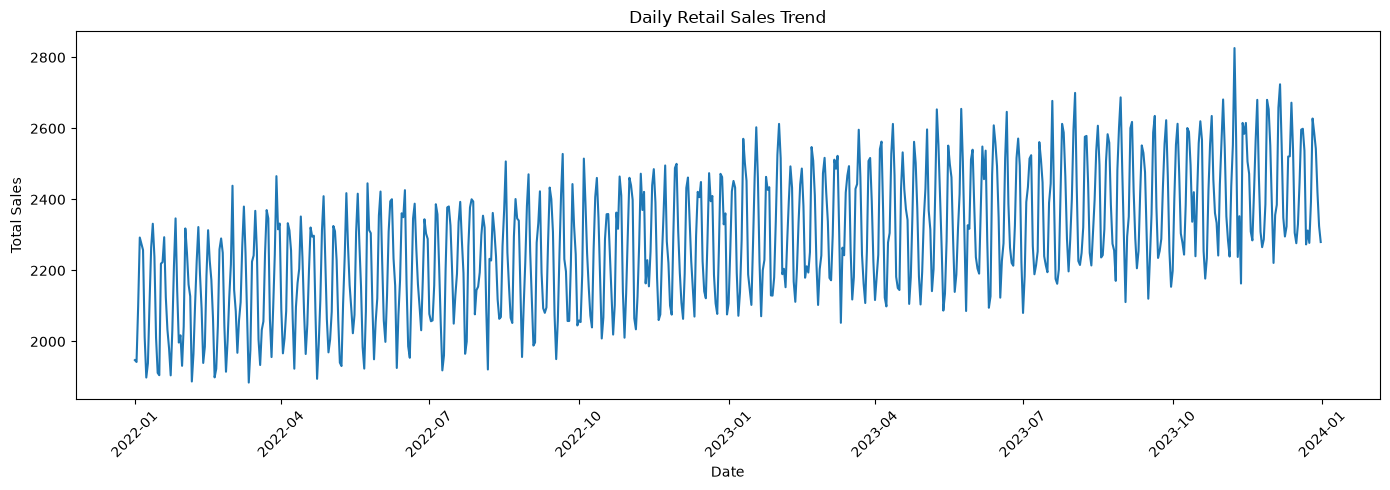

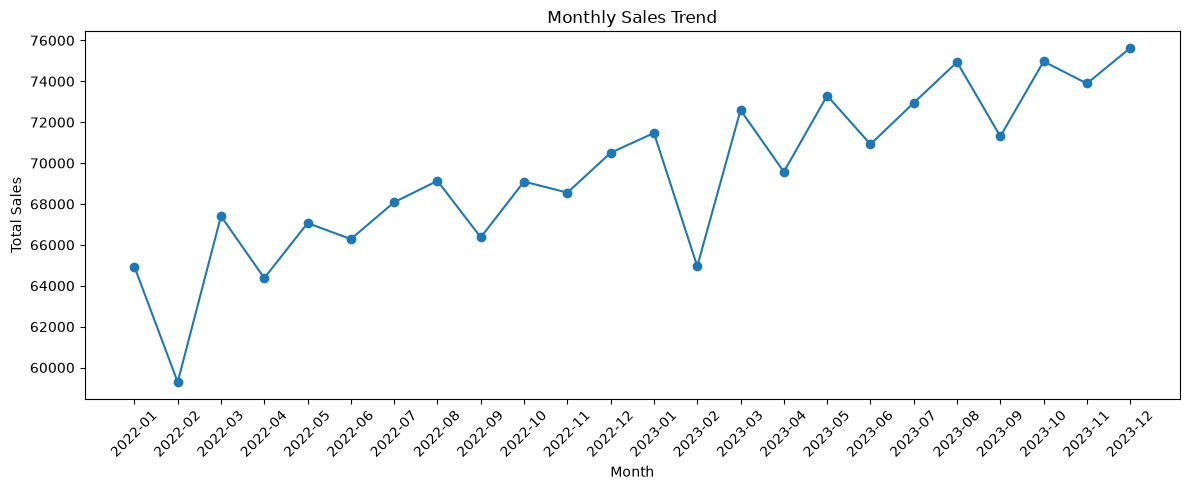

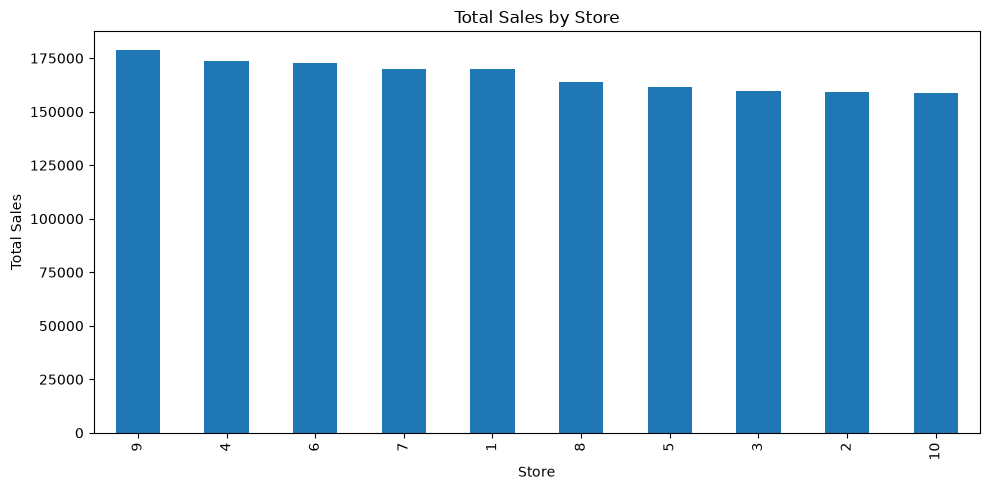


Average Sales by Promotion Status:
promo
0    222.469076
1    251.973218
Name: sales, dtype: float64


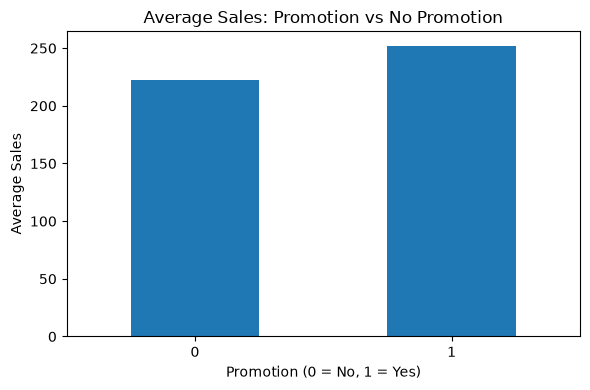


Average Sales by Holiday Status:
holiday
0    224.357538
1    263.518513
Name: sales, dtype: float64


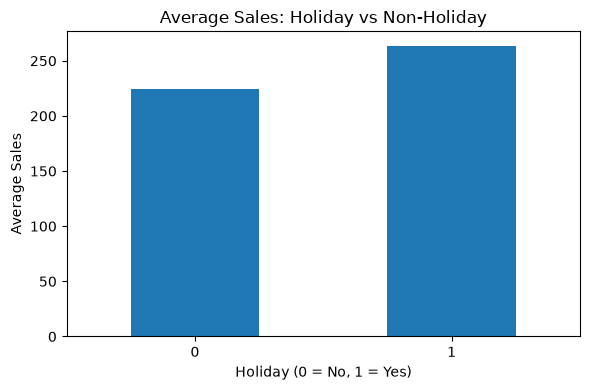


Training Records: 5840
Testing Records: 1460

Random Forest Model Trained Successfully!

MODEL PERFORMANCE
MAE : 6.57
RMSE: 8.29
R² Score: 0.8811

Actual vs Predicted:


,date,store,sales,promo,holiday,predicted_sales
5840,2023-08-08,4,248.48,0,0,255.35290
5841,2023-08-08,5,237.41,0,0,240.40200
5842,2023-08-08,8,266.15,1,0,275.39180
5843,2023-08-08,9,290.91,1,0,291.45830
5844,2023-08-08,6,285.24,1,0,285.58815
5845,2023-08-08,2,235.43,0,0,232.77825
5846,2023-08-08,3,265.32,1,0,267.67045
5847,2023-08-08,7,257.28,0,0,247.68795
5848,2023-08-08,1,251.04,0,0,252.79725
5849,2023-08-08,10,239.08,0,0,226.29220


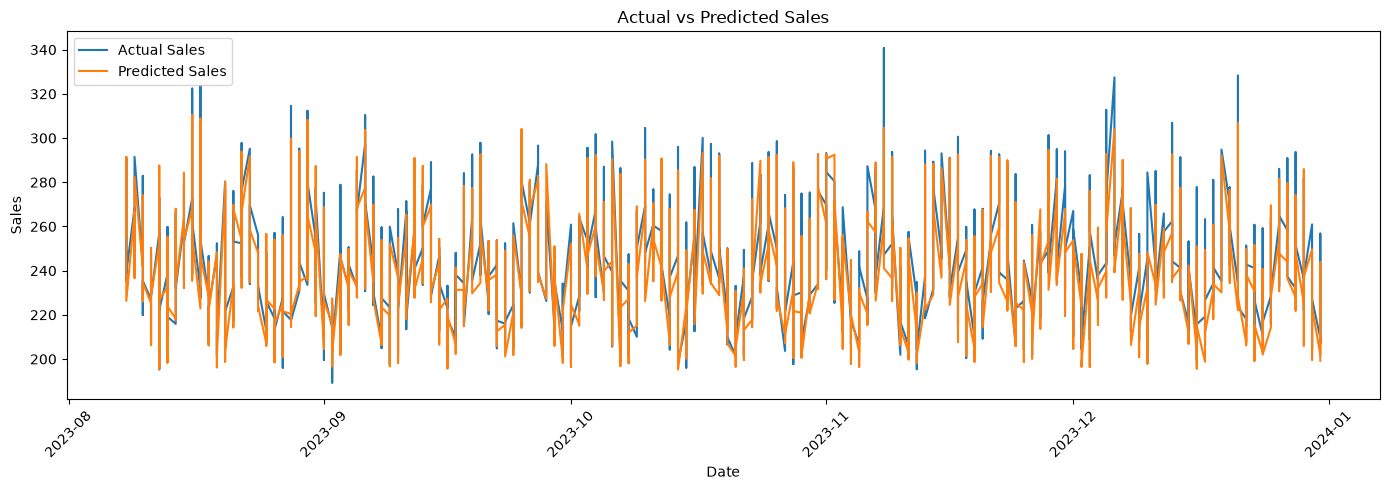


Feature Importance:


,Feature,Importance
6,day_of_week,0.289371
2,holiday,0.224187
1,promo,0.212870
0,store,0.120830
3,year,0.072840
7,week_of_year,0.039148
4,month,0.017503
5,day,0.017449
8,is_weekend,0.005801


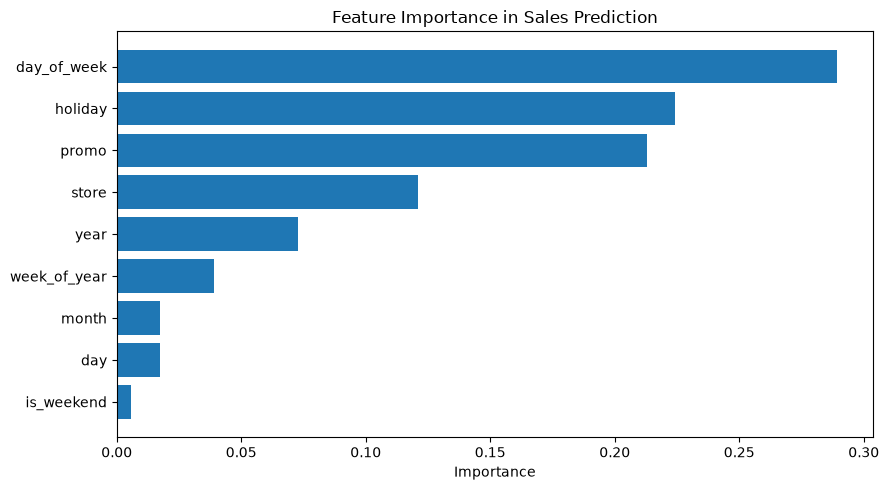


Future Forecast:


,date,store,promo,holiday,year,month,day,day_of_week,week_of_year,is_weekend,predicted_sales
0,2024-01-01,1,0,0,2024,1,1,0,1,0,223.51170
1,2024-01-02,1,0,0,2024,1,2,1,1,0,236.02670
2,2024-01-03,1,0,0,2024,1,3,2,1,0,240.54735
3,2024-01-04,1,0,0,2024,1,4,3,1,0,232.96780
4,2024-01-05,1,0,0,2024,1,5,4,1,0,218.05225
5,2024-01-06,1,0,0,2024,1,6,5,1,1,205.37210
6,2024-01-07,1,0,0,2024,1,7,6,1,1,210.36715
7,2024-01-08,1,0,0,2024,1,8,0,2,0,223.60155
8,2024-01-09,1,0,0,2024,1,9,1,2,0,235.86875
9,2024-01-10,1,0,0,2024,1,10,2,2,0,243.14940


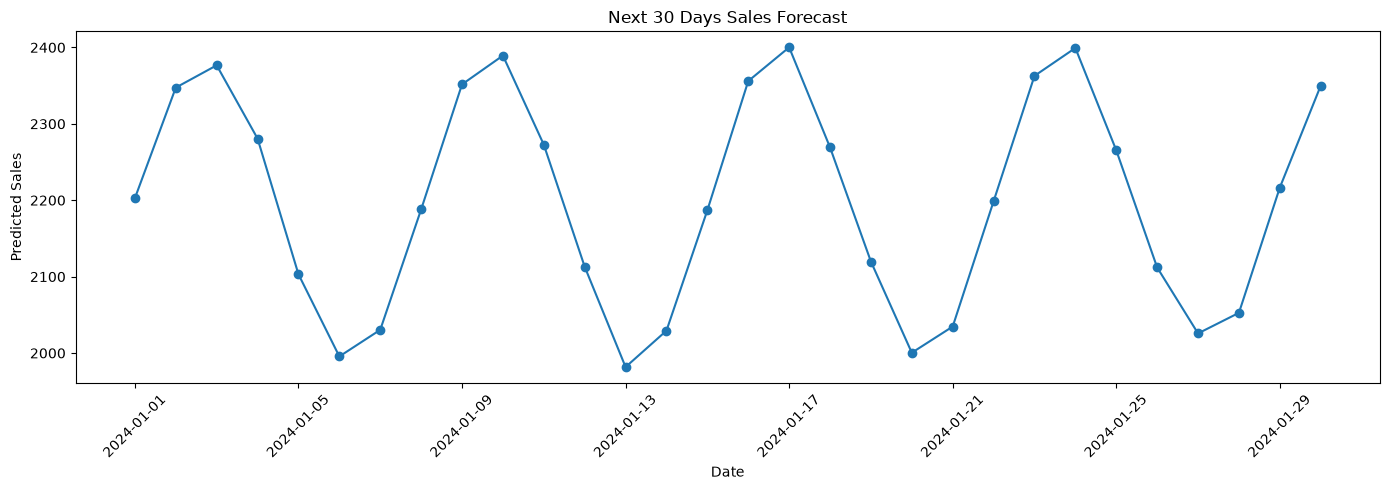


TASK 3 OUTPUT FILES CREATED
1. Task3_Actual_vs_Predicted.csv
2. Task3_30_Day_Sales_Forecast.csv
3. Task3_Feature_Importance.csv

TASK 3 PYTHON ANALYSIS COMPLETED SUCCESSFULLY!


In [5]:
# ============================================================
# THIRANEX TASK 3
# RETAIL SALES FORECASTING USING HISTORICAL DATA
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


# -----------------------------
# 2. LOAD DATASET
# -----------------------------
df = pd.read_csv("store_sales.csv")

print("\nDataset loaded successfully!")
print("Original Shape:", df.shape)


# -----------------------------
# 3. BASIC DATA INSPECTION
# -----------------------------
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


# -----------------------------
# 4. DATA CLEANING
# -----------------------------

# Convert date column
df["date"] = pd.to_datetime(df["date"])

# Remove duplicate rows
df = df.drop_duplicates()

# Sort data by store and date
df = df.sort_values(["store", "date"]).reset_index(drop=True)

print("\nAfter Cleaning:")
print("Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())


# -----------------------------
# 5. FEATURE ENGINEERING
# -----------------------------

# Date features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)

# Weekend indicator
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

print("\nFeature Engineering Completed!")

display(df.head())


# -----------------------------
# 6. SALES TREND VISUALIZATION
# -----------------------------

daily_sales = df.groupby("date")["sales"].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales["date"], daily_sales["sales"])
plt.title("Daily Retail Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# -----------------------------
# 7. MONTHLY SALES TREND
# -----------------------------

monthly_sales = (
    df.groupby(["year", "month"])["sales"]
    .sum()
    .reset_index()
)

monthly_sales["period"] = (
    monthly_sales["year"].astype(str)
    + "-"
    + monthly_sales["month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["period"], monthly_sales["sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# -----------------------------
# 8. STORE-WISE SALES
# -----------------------------

store_sales = (
    df.groupby("store")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
store_sales.plot(kind="bar")
plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


# -----------------------------
# 9. PROMOTION IMPACT
# -----------------------------

promo_sales = df.groupby("promo")["sales"].mean()

print("\nAverage Sales by Promotion Status:")
print(promo_sales)

plt.figure(figsize=(6, 4))
promo_sales.plot(kind="bar")
plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# -----------------------------
# 10. HOLIDAY IMPACT
# -----------------------------

holiday_sales = df.groupby("holiday")["sales"].mean()

print("\nAverage Sales by Holiday Status:")
print(holiday_sales)

plt.figure(figsize=(6, 4))
holiday_sales.plot(kind="bar")
plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday (0 = No, 1 = Yes)")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# 11. MACHINE LEARNING MODEL
# ============================================================

# Features used for prediction
features = [
    "store",
    "promo",
    "holiday",
    "year",
    "month",
    "day",
    "day_of_week",
    "week_of_year",
    "is_weekend"
]

X = df[features]
y = df["sales"]


# -----------------------------
# 12. TIME-BASED TRAIN TEST SPLIT
# -----------------------------

# Sort by date before splitting
model_df = df.sort_values("date").reset_index(drop=True)

X = model_df[features]
y = model_df["sales"]

split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


# -----------------------------
# 13. RANDOM FOREST MODEL
# -----------------------------

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully!")


# -----------------------------
# 14. PREDICTIONS
# -----------------------------

y_pred = model.predict(X_test)


# -----------------------------
# 15. MODEL EVALUATION
# -----------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n==============================")
print("MODEL PERFORMANCE")
print("==============================")

print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 4))


# -----------------------------
# 16. ACTUAL VS PREDICTED
# -----------------------------

results = model_df.iloc[split_index:][
    ["date", "store", "sales", "promo", "holiday"]
].copy()

results["predicted_sales"] = y_pred

print("\nActual vs Predicted:")
display(results.head(10))


# -----------------------------
# 17. ACTUAL VS PREDICTED GRAPH
# -----------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    results["date"],
    results["sales"],
    label="Actual Sales"
)

plt.plot(
    results["date"],
    results["predicted_sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# -----------------------------
# 18. FEATURE IMPORTANCE
# -----------------------------

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFeature Importance:")
display(importance)

plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.title("Feature Importance in Sales Prediction")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# ============================================================
# 19. FUTURE SALES FORECAST
# ============================================================

# Forecast next 30 days for each store

last_date = df["date"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

stores = sorted(df["store"].unique())

future_data = []

for store in stores:
    for date in future_dates:

        future_data.append({
            "date": date,
            "store": store,

            # Assume no promotion/holiday information is known
            "promo": 0,
            "holiday": 0,

            "year": date.year,
            "month": date.month,
            "day": date.day,
            "day_of_week": date.dayofweek,
            "week_of_year": date.isocalendar().week,
            "is_weekend": int(date.dayofweek >= 5)
        })

future_df = pd.DataFrame(future_data)


# Predict future sales
future_df["predicted_sales"] = model.predict(
    future_df[features]
)

print("\nFuture Forecast:")
display(future_df.head(10))


# -----------------------------
# 20. FUTURE SALES SUMMARY
# -----------------------------

future_summary = (
    future_df.groupby("date")["predicted_sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    future_summary["date"],
    future_summary["predicted_sales"],
    marker="o"
)

plt.title("Next 30 Days Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 21. SAVE OUTPUT FILES
# ============================================================

results.to_csv(
    "Task3_Actual_vs_Predicted.csv",
    index=False
)

future_df.to_csv(
    "Task3_30_Day_Sales_Forecast.csv",
    index=False
)

importance.to_csv(
    "Task3_Feature_Importance.csv",
    index=False
)

print("\n==============================")
print("TASK 3 OUTPUT FILES CREATED")
print("==============================")

print("1. Task3_Actual_vs_Predicted.csv")
print("2. Task3_30_Day_Sales_Forecast.csv")
print("3. Task3_Feature_Importance.csv")

print("\nTASK 3 PYTHON ANALYSIS COMPLETED SUCCESSFULLY!")